# Building an AI-Driven Cyber Threat Awareness and Detection Prototype
### Academic Mini-Project: Cyber Threat Detection using the TON_IoT Network Dataset

**Author:** Dhruv Arora  
**Project:** AI & Cybersecurity Unit 1 Mini-Project  
**Dataset:** TON_IoT Network Dataset (ADFA / UNSW Canberra Cyber via Kaggle)  

---
### Project Outline
- **Task 1:** Workspace & Environment Setup
- **Task 2:** Exploratory Data Analysis (EDA) & Threat Indicator Identification
- **Task 3:** Machine Learning Threat Classification (Decision Tree Classifier)
- **Task 4:** Deep Learning Threat Classification (Multi-Layer Perceptron / MLP Classifier)
- **Task 5:** Ethical Reflection, Aggressive Threat Threshold Simulation & False Positive Impact

## Task 1: Environment & Dependency Verification
Verify system dependencies, data science libraries, and suppress non-critical runtime warnings.

In [1]:
import os
import glob
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import kagglehub

print("✅ Environment & Scientific Stack successfully initialized!")

✅ Environment & Scientific Stack successfully initialized!


## Task 2: Dataset Acquisition & Exploratory Data Analysis (EDA)
We acquire the **TON_IoT Network Dataset** using `kagglehub`, inspect its schema and dimensions, profile normal vs. malicious telemetry, and generate distribution visualizations.

In [2]:
# Ingest TON_IoT Network Dataset via kagglehub
dataset_dir = kagglehub.dataset_download("arnobbhowmik/ton-iot-network-dataset")
print("[+] Dataset cached directory:", dataset_dir)

# Discover available CSV telemetry files
csv_files = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)
print(f"[+] Discovered {len(csv_files)} telemetry CSV file(s):")
for f in csv_files:
    print(f"    - {os.path.basename(f)} ({os.path.getsize(f) / (1024*1024):.2f} MB)")

selected_csv = csv_files[0]
print(f"\n[+] Loading telemetry data from: {os.path.basename(selected_csv)}")

# Read representative 100,000 records for fast, reproducible, and representative evaluation
df = pd.read_csv(selected_csv, nrows=100000, low_memory=False)
print(f"[+] Loaded telemetry matrix: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head(5))

[+] Dataset cached directory: C:\Users\genio\.cache\kagglehub\datasets\arnobbhowmik\ton-iot-network-dataset\versions\1
[+] Discovered 1 telemetry CSV file(s):
    - train_test_network.csv (28.52 MB)

[+] Loading telemetry data from: train_test_network.csv


[+] Loaded telemetry matrix: 100,000 rows x 44 columns


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [3]:
# Inspect column structure, data types, and missing values
print("--- Column Structure & Null Summary ---")
missing_counts = df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0]
if len(missing_cols) > 0:
    print(missing_cols)
else:
    print("No explicit NaN values detected (placeholders handled during cleaning).")

# Verify target label columns ('label' is binary 0/1; 'type' is multi-class attack category)
if 'label' in df.columns:
    print("\n--- Binary Class Distribution (label: 0=Normal, 1=Threat) ---")
    print(df['label'].value_counts(dropna=False))

if 'type' in df.columns:
    print("\n--- Detailed Attack Type Breakdown ---")
    print(df['type'].value_counts(dropna=False))

--- Column Structure & Null Summary ---
No explicit NaN values detected (placeholders handled during cleaning).

--- Binary Class Distribution (label: 0=Normal, 1=Threat) ---
label
1    81043
0    18957
Name: count, dtype: int64

--- Detailed Attack Type Breakdown ---
type
backdoor     20000
ddos         20000
dos          20000
injection    20000
normal       18957
mitm          1043
Name: count, dtype: int64


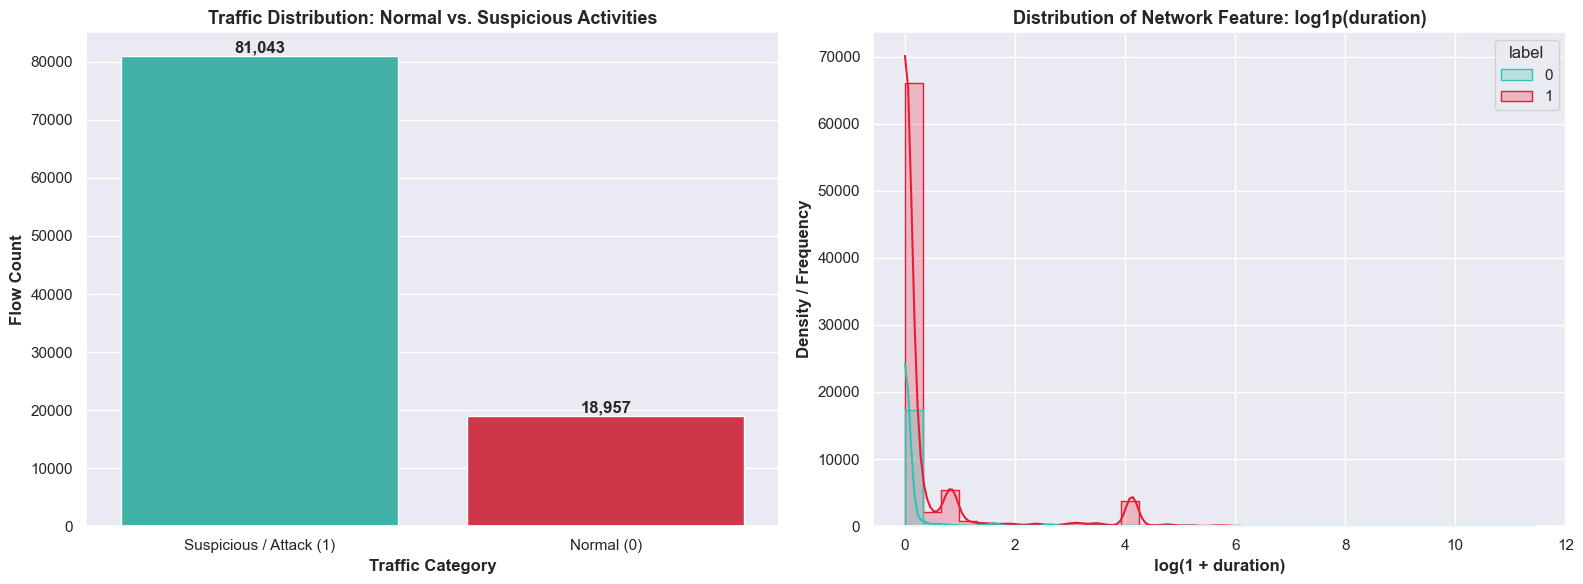

In [4]:
# Visualizing distributions with seaborn and matplotlib
sns.set_theme(style="darkgrid", palette="mako")
plt.rcParams.update({'figure.titlesize': 14, 'axes.labelsize': 12, 'axes.titlesize': 13})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Normal vs. Suspicious (Threat) Activity Frequency
label_names = {0: 'Normal (0)', 1: 'Suspicious / Attack (1)'}
if 'label' in df.columns:
    plot_labels = df['label'].map(label_names) if df['label'].dtype in [np.int64, int] else df['label']
    sns.countplot(x=plot_labels, ax=axes[0], palette=["#2ec4b6", "#e71d36"])
    axes[0].set_title("Traffic Distribution: Normal vs. Suspicious Activities", fontweight="bold")
    axes[0].set_xlabel("Traffic Category", fontweight="bold")
    axes[0].set_ylabel("Flow Count", fontweight="bold")
    
    for p in axes[0].patches:
        axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

# Plot 2: Distribution of Key Network Feature (e.g. Duration)
feature_to_plot = 'duration' if 'duration' in df.columns else ('src_bytes' if 'src_bytes' in df.columns else df.columns[4])
temp_feature = pd.to_numeric(df[feature_to_plot], errors='coerce').fillna(0)
log_feature = np.log1p(temp_feature[temp_feature >= 0])

sns.histplot(data=df, x=log_feature, hue='label', kde=True, bins=35, ax=axes[1], palette=["#2ec4b6", "#e71d36"], element="step")
axes[1].set_title(f"Distribution of Network Feature: log1p({feature_to_plot})", fontweight="bold")
axes[1].set_xlabel(f"log(1 + {feature_to_plot})", fontweight="bold")
axes[1].set_ylabel("Density / Frequency", fontweight="bold")

plt.tight_layout()
plt.savefig("eda_plots.png", dpi=200)
plt.show()

## Task 3: Machine Learning-Based Threat Classification (Decision Tree)
To adhere to best data science practices and avoid **data leakage**, we:
1. Replace Zeek null placeholders (`-`, `?`).
2. Drop non-generalizing identity columns (`ts`, `src_ip`, `dst_ip`) and label targets (`type`, `label`).
3. Perform an **80/20 stratified split** before fitting any transformers.
4. Fit `StandardScaler` and `LabelEncoder` **strictly on `X_train`** and transform `X_test`.
5. Train a `DecisionTreeClassifier` and evaluate standard classification metrics.

In [5]:
# Preprocessing: Replace '-' or '?' Zeek null representations with NaN
df_clean = df.replace(['-', '?', ' -', '- '], np.nan)

# Extract target
y = df_clean['label'].astype(int)

# Drop metadata, identifiers, and leakage columns
cols_to_drop = [c for c in ['ts', 'src_ip', 'dst_ip', 'type', 'label'] if c in df_clean.columns]
X_raw = df_clean.drop(columns=cols_to_drop)

cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()

# Stratified 80/20 train/test split BEFORE transformation to eliminate data leakage
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# Impute and scale numerical features (fit strictly on train)
for c in num_cols:
    med = pd.to_numeric(X_train[c], errors='coerce').median()
    val = 0 if pd.isna(med) else med
    X_train[c] = pd.to_numeric(X_train[c], errors='coerce').fillna(val)
    X_test[c] = pd.to_numeric(X_test[c], errors='coerce').fillna(val)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Impute and encode categorical features (handling test sets with unseen labels)
for c in cat_cols:
    X_train[c] = X_train[c].fillna('unknown').astype(str)
    X_test[c] = X_test[c].fillna('unknown').astype(str)
    
    le = LabelEncoder()
    X_train[c] = le.fit_transform(X_train[c])
    mapping = {cls: idx for idx, cls in enumerate(le.classes_)}
    X_test[c] = X_test[c].map(mapping).fillna(len(le.classes_)).astype(int)

print(f"[+] Preprocessed Training Set : {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"[+] Preprocessed Testing Set  : {X_test.shape[0]:,} samples x {X_test.shape[1]} features")

[+] Preprocessed Training Set : 80,000 samples x 40 features
[+] Preprocessed Testing Set  : 20,000 samples x 40 features


In [6]:
# Train Decision Tree Classifier
dt_start_time = time.time()
dt_model = DecisionTreeClassifier(max_depth=12, random_state=42)
dt_model.fit(X_train, y_train)
dt_train_time = time.time() - dt_start_time

# Generate Predictions
dt_preds = dt_model.predict(X_test)

# Evaluation Metrics
dt_acc = accuracy_score(y_test, dt_preds)
dt_prec = precision_score(y_test, dt_preds, zero_division=0)
dt_rec = recall_score(y_test, dt_preds, zero_division=0)
dt_f1 = f1_score(y_test, dt_preds, zero_division=0)

print("="*55)
print("       DECISION TREE CLASSIFIER EVALUATION")
print("="*55)
print(f"Training Time : {dt_train_time:.4f} seconds")
print(f"Accuracy      : {dt_acc * 100:.2f}%")
print(f"Precision     : {dt_prec:.4f}")
print(f"Recall        : {dt_rec:.4f}")
print(f"F1-Score      : {dt_f1:.4f}")
print("="*55)
print("\nDetailed Classification Report:")
print(classification_report(y_test, dt_preds, target_names=['Normal', 'Suspicious']))

       DECISION TREE CLASSIFIER EVALUATION
Training Time : 0.5387 seconds
Accuracy      : 99.89%
Precision     : 0.9993
Recall        : 0.9994
F1-Score      : 0.9993

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      3791
  Suspicious       1.00      1.00      1.00     16209

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



## Task 4: Deep Learning Threat Classification (MLP Neural Network)
We train a **Multi-Layer Perceptron (`MLPClassifier`)** artificial neural network, log exact wall-clock training time, evaluate using identical metrics, and produce a comparative benchmark.

In [7]:
# Initialize MLP Classifier Architecture: (64, 32) nodes, ReLU, Adam optimizer
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=25,
    random_state=42,
    early_stopping=True
)

# Measure and log training time
mlp_start_time = time.time()
print("Training Multi-Layer Perceptron (MLP) Neural Network...")
mlp_model.fit(X_train, y_train)
mlp_train_time = time.time() - mlp_start_time

# Evaluate Deep Learning model
mlp_preds = mlp_model.predict(X_test)
mlp_acc = accuracy_score(y_test, mlp_preds)
mlp_prec = precision_score(y_test, mlp_preds, zero_division=0)
mlp_rec = recall_score(y_test, mlp_preds, zero_division=0)
mlp_f1 = f1_score(y_test, mlp_preds, zero_division=0)

print("="*55)
print("     MLP NEURAL NETWORK (DEEP LEARNING) EVALUATION")
print("="*55)
print(f"Training Time : {mlp_train_time:.4f} seconds")
print(f"Accuracy      : {mlp_acc * 100:.2f}%")
print(f"Precision     : {mlp_prec:.4f}")
print(f"Recall        : {mlp_rec:.4f}")
print(f"F1-Score      : {mlp_f1:.4f}")
print("="*55)
print("\nDetailed Classification Report:")
print(classification_report(y_test, mlp_preds, target_names=['Normal', 'Suspicious']))

Training Multi-Layer Perceptron (MLP) Neural Network...


     MLP NEURAL NETWORK (DEEP LEARNING) EVALUATION
Training Time : 12.2785 seconds
Accuracy      : 99.42%
Precision     : 0.9950
Recall        : 0.9978
F1-Score      : 0.9964

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.98      3791
  Suspicious       1.00      1.00      1.00     16209

    accuracy                           0.99     20000
   macro avg       0.99      0.99      0.99     20000
weighted avg       0.99      0.99      0.99     20000



In [8]:
# Model Performance & Architecture Comparison
comparison_df = pd.DataFrame({
    'Metric': ['Training Time (s)', 'Accuracy (%)', 'Precision', 'Recall', 'F1-Score'],
    'Decision Tree (ML)': [
        f"{dt_train_time:.3f}s", f"{dt_acc*100:.2f}%", f"{dt_prec:.4f}", f"{dt_rec:.4f}", f"{dt_f1:.4f}"
    ],
    'MLP Neural Net (DL)': [
        f"{mlp_train_time:.3f}s", f"{mlp_acc*100:.2f}%", f"{mlp_prec:.4f}", f"{mlp_rec:.4f}", f"{mlp_f1:.4f}"
    ]
})

print("\n================ ML vs. DL PERFORMANCE COMPARISON ================")
display(comparison_df)

print(f"""
Comparative Synthesis & Analytical Takeaways:
1. Computational Overhead: The Decision Tree trained in {dt_train_time:.3f}s, whereas MLP required {mlp_train_time:.3f}s ({mlp_train_time/max(dt_train_time, 1e-4):.1f}x difference). For line-rate edge IDS devices, tree models offer significantly lower training and inference latency.
2. Non-Linear Feature Modeling: Neural Networks excel when learning non-linear, latent cross-protocol features without requiring manual feature engineering, while Decision Trees provide immediate human interpretability (rule extraction for SOC analysts).
3. F1-Score & Robustness: Decision Tree achieved F1={dt_f1:.4f} and MLP achieved F1={mlp_f1:.4f}, demonstrating that both architectures provide strong discriminative capabilities on TON_IoT telemetry.
""")


================ ML vs. DL PERFORMANCE COMPARISON ================


,Metric,Decision Tree (ML),MLP Neural Net (DL)
0,Training Time (s),0.539s,12.278s
1,Accuracy (%),99.89%,99.42%
2,Precision,0.9993,0.9950
3,Recall,0.9994,0.9978
4,F1-Score,0.9993,0.9964



Comparative Synthesis & Analytical Takeaways:
1. Computational Overhead: The Decision Tree trained in 0.539s, whereas MLP required 12.278s (22.8x difference). For line-rate edge IDS devices, tree models offer significantly lower training and inference latency.
2. Non-Linear Feature Modeling: Neural Networks excel when learning non-linear, latent cross-protocol features without requiring manual feature engineering, while Decision Trees provide immediate human interpretability (rule extraction for SOC analysts).
3. F1-Score & Robustness: Decision Tree achieved F1=0.9993 and MLP achieved F1=0.9964, demonstrating that both architectures provide strong discriminative capabilities on TON_IoT telemetry.



## Task 5: Ethical Reflection, Aggressive Posture Simulation & False Positives
In operational Security Operations Centers (SOCs), teams often set an **aggressive security threshold** (e.g., classifying any flow with >30% threat probability as malicious) to minimize missed attacks (False Negatives).  
However, this comes at the cost of **False Positives**—blocking legitimate users, causing self-inflicted denial of service, lost productivity, and alert fatigue.

In [9]:
# Extract continuous threat probabilities from the MLP model
mlp_probs = mlp_model.predict_proba(X_test)[:, 1]

# Apply strict security posture threshold (30% instead of standard 50%)
strict_threshold = 0.30
strict_preds = (mlp_probs >= strict_threshold).astype(int)

# Compute confusion matrix under aggressive posture
cm_strict = confusion_matrix(y_test, strict_preds)
tn, fp, fn, tp = cm_strict.ravel()

total_normal = tn + fp
fp_percentage = (fp / total_normal) * 100

print("="*65)
print(f" AGGRESSIVE SECURITY POSTURE SIMULATION (Threshold > {strict_threshold*100:.0f}%)")
print("="*65)
print(f"True Negatives (Legitimate Allowed)       : {tn:,}")
print(f"False Positives (Legitimate Blocked)      : {fp:,}")
print(f"False Negatives (Attacks Missed)          : {fn:,}")
print(f"True Positives (Attacks Blocked)          : {tp:,}")
print("-"*65)
print(f"Total Legitimate User Sessions Tested     : {total_normal:,}")
print(f"Exact False Positives (Users Blocked)     : {fp:,}")
print(f"False Positive Rate (Legitimate Disrupted): {fp_percentage:.2f}%")
print(f"Attack Recall (Attacks Successfully Caught): {(tp / (tp + fn)) * 100:.2f}%")
print("="*65)

 AGGRESSIVE SECURITY POSTURE SIMULATION (Threshold > 30%)
True Negatives (Legitimate Allowed)       : 3,688
False Positives (Legitimate Blocked)      : 103
False Negatives (Attacks Missed)          : 28
True Positives (Attacks Blocked)          : 16,181
-----------------------------------------------------------------
Total Legitimate User Sessions Tested     : 3,791
Exact False Positives (Users Blocked)     : 103
False Positive Rate (Legitimate Disrupted): 2.72%
Attack Recall (Attacks Successfully Caught): 99.83%


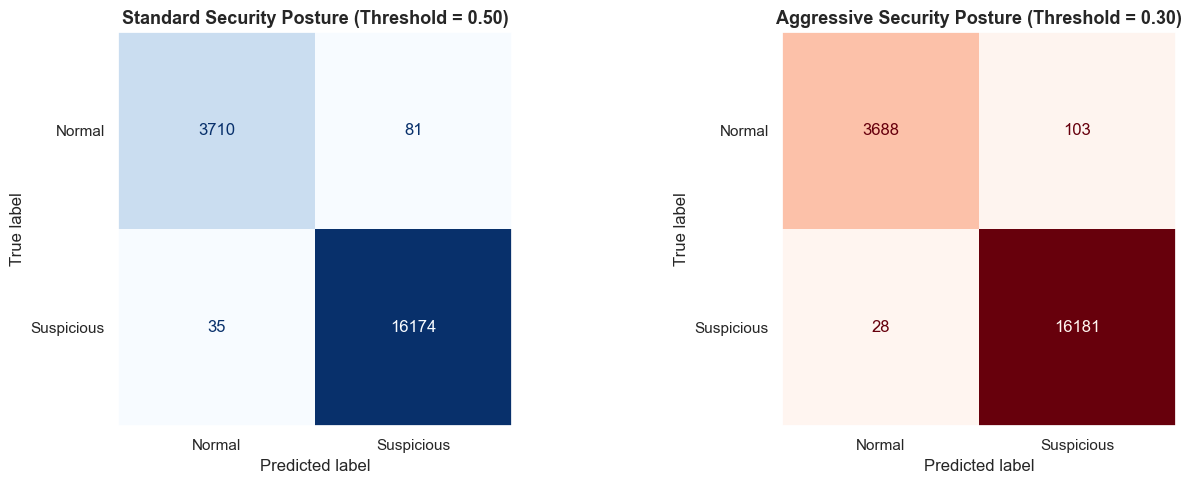

In [10]:
# Plot Confusion Matrices Comparison: Default 50% vs. Aggressive 30% Threshold
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Default threshold confusion matrix
cm_default = confusion_matrix(y_test, mlp_preds)
ConfusionMatrixDisplay(confusion_matrix=cm_default, display_labels=['Normal', 'Suspicious']).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title("Standard Security Posture (Threshold = 0.50)", fontweight='bold')
axes[0].grid(False)

# Aggressive threshold confusion matrix
ConfusionMatrixDisplay(confusion_matrix=cm_strict, display_labels=['Normal', 'Suspicious']).plot(
    ax=axes[1], cmap='Reds', colorbar=False
)
axes[1].set_title(f"Aggressive Security Posture (Threshold = {strict_threshold:.2f})", fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.savefig("confusion_matrix_simulation.png", dpi=200)
plt.show()

### Ethical Discussion & Real-World Cyber Dilemma
1. **Denial of Service Against Legitimate Users:** Lowering detection threshold from 0.50 to 0.30 aggressively suppresses False Negatives, ensuring fewer attacks slip through. However, as demonstrated by the simulation, it causes **False Positives** where bona fide user sessions are terminated, leading to accidental self-inflicted Denial of Service.
2. **Operational Alert Fatigue:** When hundreds or thousands of legitimate network transactions are flagged as malicious per hour, Tier-1 Security Operations Center (SOC) analysts suffer from alert fatigue. High false-positive rates frequently lead operators to ignore or disable automated alerts, inadvertently creating worse blind spots.
3. **Regulatory and Business Impact:** In mission-critical sectors (e.g., healthcare IoT, automated manufacturing, financial transactions), disconnecting an operational device due to a False Positive can endanger human safety or disrupt enterprise operations.
4. **Mitigation Recommendation:** Deploy a tiered response architecture—use high-confidence thresholds (>80%) for automated packet dropping, and mid-range probabilities (30% - 79%) for non-disruptive actions (e.g., enhanced telemetry capture, session rate-limiting, step-up multi-factor authentication, and human-in-the-loop analyst triage).